<a href="https://colab.research.google.com/github/KadeejaHibaPT/AML_lab/blob/main/AMLexp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linear Ridge Regression MSE: 0.3644
Kernel Ridge Regression MSE: 0.0171


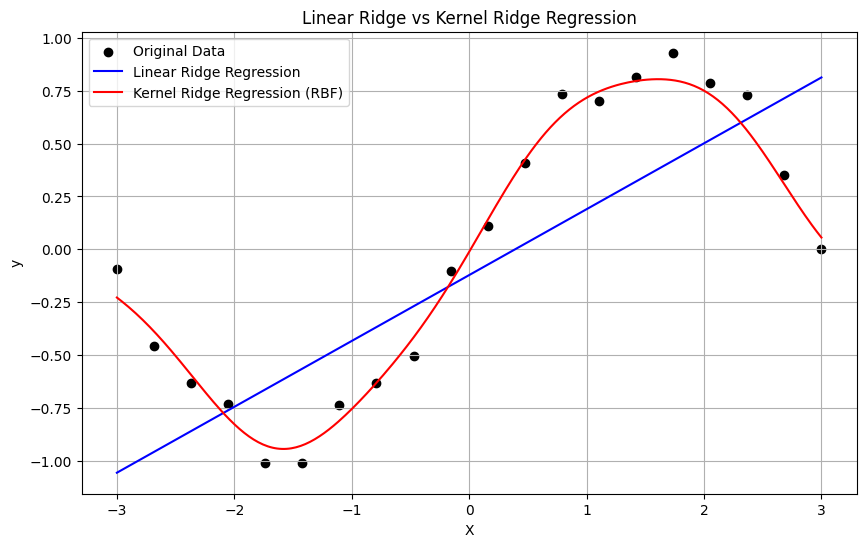


Comparison:
Kernel Ridge Regression performs better.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_squared_error

np.random.seed(42)

X = np.linspace(-3, 3, 20).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 20)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

krr = KernelRidge(alpha=0.1, kernel='rbf', gamma=1.0)
krr.fit(X_train, y_train)
y_pred_krr = krr.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
mse_krr = mean_squared_error(y_test, y_pred_krr)

print("Linear Ridge Regression MSE:", round(mse_ridge, 4))
print("Kernel Ridge Regression MSE:", round(mse_krr, 4))

X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)
y_ridge_curve = ridge.predict(X_plot)
y_krr_curve = krr.predict(X_plot)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='black', label='Original Data')
plt.plot(X_plot, y_ridge_curve, color='blue',
         label='Linear Ridge Regression')
plt.plot(X_plot, y_krr_curve, color='red',
         label='Kernel Ridge Regression (RBF)')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Ridge vs Kernel Ridge Regression')
plt.legend()
plt.grid(True)
plt.show()

print("\nComparison:")
if mse_krr < mse_ridge:
    print("Kernel Ridge Regression performs better.")
elif mse_ridge < mse_krr:
    print("Linear Ridge Regression performs better.")
else:
    print("Both models have equal MSE.")
